## Telco Customer Churn — analiza i przewidywanie odejść klientów

1. Cel projektu

Celem projektu jest analiza danych klientów firmy telekomunikacyjnej oraz sprawdzenie, czy na podstawie dostępnych informacji można przewidywać odejście klienta (customer churn).

Projekt obejmuje analizę eksploracyjną danych (EDA), przygotowanie danych do modelowania, budowę modelu klasyfikacyjnego oraz ocenę jego skuteczności.

2. Pytanie badawcze

Czy wybrane cechy klientów i warunki korzystania z usług telekomunikacyjnych mogą pomóc zidentyfikować klientów, którzy rezygnują z usług?

3. Zbiór danych

W projekcie wykorzystano zbiór Telco Customer Churn udostępniony na platformie Kaggle.

Źródło danych: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

Dane zawierają informacje o klientach, używanych przez nich usługach, rodzaju umowy i opłatach. Kolumna Churn informuje, czy klient zrezygnował z usług.

4. Plan pracy

- Wczytanie danych i sprawdzenie ich struktury.

- Ocena jakości danych i przygotowanie ich do analizy.

- Analiza eksploracyjna oraz identyfikacja zależności między cechami klientów a odejściami.

- Przygotowanie danych i budowa modelu klasyfikacyjnego.

- Ocena wyników modelu i porównanie ich z modelem bazowym.

- Sformułowanie wniosków i rekomendacji biznesowych.

5. Oczekiwany rezultat

Rezultatem projektu będzie działający proces analizy danych i modelowania oraz wnioski biznesowe poparte wynikami analizy.

6. Użyte oprogramowanie i sposób dostarczenia projektu

Projekt napisany w Visual Studio Code, wysłany na repozytorium GitHub.

### Import bibliotek i konfiguracja środowiska

Na początek zostaną zaimportowane biblioteki niezbędne do wczytywania danych, ich analizy oraz przygotowania wizualizacji.

Do realizacji projektu wykorzystane zostaną:

- **Pandas** — wczytywanie, przetwarzanie i analiza danych tabelarycznych.
- **NumPy** — operacje numeryczne.
- **Matplotlib** — tworzenie wykresów i wizualizacja wyników.
- **Seaborn** — tworzenie wykresów statystycznych.
- **Scikit-learn** — przygotowanie danych, budowa modeli klasyfikacyjnych i ocena ich skuteczności (import nastąpi na etapie preprocessingu danych).

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

### Wczytanie zbioru danych

Dane zapisane w pliku CSV zostaną wczytane do obiektu Pandas
DataFrame, czyli tabeli umożliwiającej dalszą analizę.

Ścieżka do zbioru danych zostanie określona względnie względem struktury katalogów projektu, tak aby ułatwić uruchomienie notebooka na innym komputerze.

Przed wczytaniem zostanie sprawdzone, czy plik znajduje się
w oczekiwanym katalogu projektu.

Po wczytaniu danych zostaną wyświetlone pierwsze rekordy,
aby sprawdzić, czy plik został odczytany prawidłowo.

In [61]:
# Ustalenie katalogu projektu
PROJECT_DIR = Path.cwd()

# Jeśli w bieżącym katalogu nie ma folderu data,
# sprawdzenie katalogu nadrzędnego
if not (PROJECT_DIR / "data").is_dir():
    PROJECT_DIR = PROJECT_DIR.parent

# Ścieżka do pliku CSV
DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

# Sprawdzenie, czy plik istnieje
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Nie znaleziono pliku danych: {DATA_PATH}"
    )

# Wczytanie danych do tabeli
df = pd.read_csv(DATA_PATH)

# Wyświetlenie pierwszych pięciu rekordów
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Pierwsze sprawdzenie danych

Po wczytaniu pliku należy sprawdzić, ile rekordów i kolumn
zawiera zbiór oraz jakie informacje znajdują się w poszczególnych
kolumnach.

Na tym etapie zostaną sprawdzone:
- liczba wierszy i kolumn,
- nazwy i typy danych,
- przykładowe rekordy.

Dzięki temu można lepiej poznać strukturę zbioru przed rozpoczęciem
dalszej analizy.

In [62]:
# Liczba wierszy i kolumn
print("Rozmiar zbioru:", df.shape)

# Informacje o kolumnach i typach danych
df.info()

Rozmiar zbioru: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non

##### Uwaga

Tu warto zwrócić uwagę na fakt, że kolumna `MonthlyCharges`, zawierająca opłaty miesięczne, ma typ liczbowy `float64`. Kolumna `TotalCharges`, zawierająca opłaty łączne, została wczytana jako tekst (`str`).

Aby umożliwić wykonywanie obliczeń na tej kolumnie, konieczna jest konwersja jej zawartości na typ liczbowy.

### Kontrola jakości danych

Przed rozpoczęciem analizy należy sprawdzić, czy zbiór zawiera brakujące wartości i powtarzające się rekordy.

Brakujące dane mogą utrudniać analizę, a duplikaty mogą wpływać na uzyskane wyniki. Dodatkowo zostanie sprawdzona liczba klientów, którzy zrezygnowali z usług.

Wyniki tej kontroli pomogą ustalić, czy dane wymagają dalszego przygotowania.

In [63]:
# Sprawdzenie brakujących wartości
print("Brakujące wartości w kolumnach:")
print(df.isnull().sum())

# Sprawdzenie liczby zduplikowanych wierszy
print("\nLiczba zduplikowanych wierszy:")
print(df.duplicated().sum())

# Sprawdzenie liczby klientów w każdej kategorii Churn
print("\nLiczba klientów według Churn:")
print(df["Churn"].value_counts())

Brakujące wartości w kolumnach:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Liczba zduplikowanych wierszy:
0

Liczba klientów według Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


Kolumna `TotalCharges` została wczytana jako typ tekstowy (`str`), dlatego przed dalszą analizą należy przekształcić ją na typ liczbowy. Następnie zostanie sprawdzone, czy konwersja ujawniła brakujące wartości.

In [64]:
# Konwersja TotalCharges na wartości liczbowe
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Sprawdzenie brakujących wartości po konwersji
print("Brakujące wartości w TotalCharges:")
print(df["TotalCharges"].isnull().sum())

# Wyświetlenie rekordów z brakującą wartością TotalCharges
df.loc[
    df["TotalCharges"].isnull(),
    ["tenure", "TotalCharges", "Churn"]
]

Brakujące wartości w TotalCharges:
11


,tenure,TotalCharges,Churn
488,0,NaN,No
753,0,NaN,No
936,0,NaN,No
1082,0,NaN,No
1340,0,NaN,No
3331,0,NaN,No
3826,0,NaN,No
4380,0,NaN,No
5218,0,NaN,No
6670,0,NaN,No


### Przygotowanie kolumny `TotalCharges`

Dodatkowa kontrola wykazała 11 pustych wartości w kolumnie `TotalCharges`. Po wyświetleniu wszystkich wybrakowanych wpisów można zauważyć, że wszystkie dotyczyły klientów ze stażem wynoszącym 0 miesięcy.

Brakujące wartości zostaną uzupełnione zerami, zgodnie z przyjętym założeniem, że dla tych rekordów łączne opłaty wynoszą 0.

In [65]:
# Uzupełnienie brakujących wartości zerami
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Kontrola wyniku
print("Brakujące wartości w całym zbiorze:")
print(df.isnull().sum().sum())

print("\nTyp danych TotalCharges:")
print(df["TotalCharges"].dtype)

Brakujące wartości w całym zbiorze:
0

Typ danych TotalCharges:
float64


### Wyniki wstępnej kontroli danych

Zbiór danych zawiera 7043 rekordy i 21 kolumn. Początkowa kontrola nie wykazała brakujących wartości rozpoznawanych przez Pandas ani identycznych zduplikowanych wierszy.

### Wykryte problemy i inne uwagi

Podczas dodatkowej kontroli kolumny TotalCharges wykryto 11 pustych wartości, które nie zostały rozpoznane jako braki danych. Wszystkie dotyczyły klientów ze stażem tenure = 0 i wartością Churn = No. Kolumnę TotalCharges przekształcono na typ liczbowy, a wykryte braki uzupełniono zerami. Przyjęto, że klienci ze stażem wynoszącym 0 miesięcy nie ponieśli dotychczas opłat.

Po uzupełnieniu braków ponownie sprawdzono kompletność danych - zbiór nie zawiera już brakujących wartości. Nie stwierdzono również identycznych zduplikowanych wierszy. Dane są przygotowane do rozpoczęcia analizy eksploracyjnej.
___________________________________________________________________________________________________________________________________________________

## Analiza eksploracyjna danych (EDA)

Analiza eksploracyjna służy do poznania struktury danych i identyfikacji zależności, które mogą być istotne dla badanego problemu.

Na początku zostanie sprawdzony rozkład zmiennej `Churn`, określającej, czy klient zrezygnował z usług. Pozwoli to ocenić liczebność obu grup klientów oraz udział odejść w całym zbiorze.

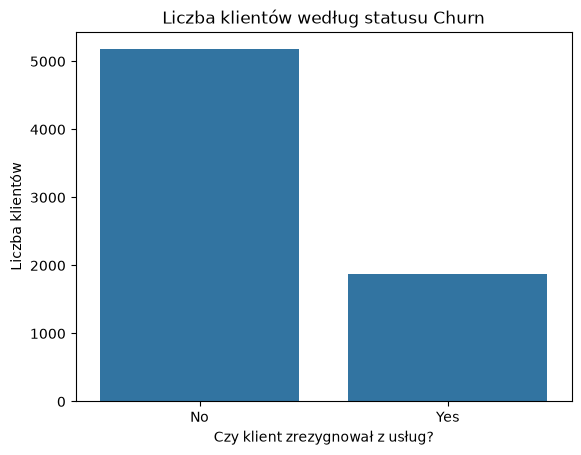

Udział klientów według Churn (%):
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


In [66]:
# Wykres liczby klientów według Churn
sns.countplot(data=df, x="Churn")

plt.title("Liczba klientów według statusu Churn")
plt.xlabel("Czy klient zrezygnował z usług?")
plt.ylabel("Liczba klientów")
plt.show()

# Udział procentowy obu grup
print("Udział klientów według Churn (%):")
print(
    (df["Churn"].value_counts(normalize=True) * 100).round(1)
)

### Rozkład zmiennej docelowej 'Churn' - wnioski

Analiza zmiennej docelowej wykazała, że 73,5% klientów pozostało przy usługach operatora (`No`), natomiast 26,5% zrezygnowało z usług (`Yes`).

Oznacza to, że klasy są niezrównoważone. Model przewidujący wyłącznie brak rezygnacji mógłby osiągnąć accuracy na poziomie około 73,5%, nie identyfikując żadnego klienta odchodzącego.

Z tego względu podczas oceny modeli szczególna uwaga zostanie zwrócona na recall i F1-score dla klasy `Yes`, a także na ROC-AUC. Pozwoli to lepiej ocenić przydatność modelu do identyfikowania klientów zagrożonych odejściem.

### Przegląd cech zbioru danych

W tej części zostanie przeprowadzony przegląd cech opisujących klientów oraz wykorzystywane przez nich usługi. Celem jest poznanie rozkładów danych, liczebności kategorii i potencjalnych zależności ze zmienną docelową `Churn`.

Kolumna `customerID` pełni funkcję identyfikatora, natomiast `Churn` jest zmienną docelową. Pozostałe kolumny będą rozpatrywane jako potencjalne cechy wejściowe modelu.

In [67]:

# Przegląd cech zbioru danych
feature_overview = pd.DataFrame({
    "Typ danych": df.dtypes.astype(str),
    "Liczba unikalnych wartości": df.nunique(),
    "Liczba braków": df.isnull().sum()
})

display(feature_overview)


,Typ danych,Liczba unikalnych wartości,Liczba braków
customerID,str,7043,0
gender,str,2,0
SeniorCitizen,int64,2,0
Partner,str,2,0
Dependents,str,2,0
tenure,int64,73,0
PhoneService,str,2,0
MultipleLines,str,3,0
InternetService,str,3,0
OnlineSecurity,str,3,0


#### Przegląd cech liczbowych zbioru danych

Dodatkowo, dla cech liczbowych (tenure, MonthlyCharges, TotalCharges) zostaną obliczone statystyki opisowe, obejmujące m.in. średnią, odchylenie standardowe, medianę, kwartyle oraz wartości minimalne i maksymalne. Pozwala to wstępnie ocenić rozkład wartości i zróżnicowanie poszczególnych zmiennych.

In [68]:

# Cechy liczbowe
numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

display(df[numeric_cols].describe().round(2))

# Liczebność kategorii w pozostałych cechach
categorical_cols = [
    col for col in df.columns
    if col not in ["customerID", "Churn"]
    and (
        df[col].dtype == "object"
        or df[col].dtype == "str"
        or col == "SeniorCitizen"
    )
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80



--- gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- SeniorCitizen ---
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--- PhoneService ---
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

--- MultipleLines ---
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- OnlineSecurity ---
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--- OnlineBackup ---
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

--- DeviceProtection ---
DeviceProtec

### Analiza zmiennych numerycznych (`tenure`, `MonthlyCharges`, `TotalCharges`) względem Churn

W celu porównania klientów, którzy zrezygnowali z usług, z klientami pozostającymi zostaną przedstawione rozkłady stażu oraz opłat miesięcznych i łącznych. Do wizualizacji zostaną wykorzystane wykresy pudełkowe, które ułatwią porównanie median i zróżnicowania wartości w obu grupach.

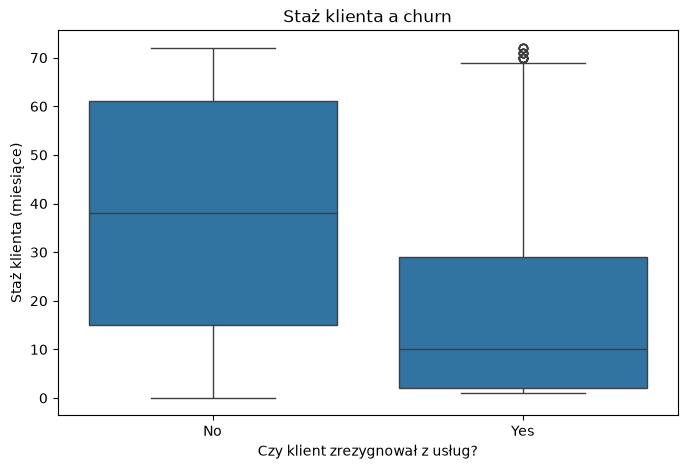

In [69]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Staż klienta a churn")
plt.xlabel("Czy klient zrezygnował z usług?")
plt.ylabel("Staż klienta (miesiące)")
plt.show()


##### `tenure` a churn - wniosek 
Klienci, którzy zrezygnowali z usług, mieli na ogół krótszy staż niż klienci pozostający. Mediana stażu wynosi około 10 miesięcy dla grupy `Churn = Yes` i około 38 miesięcy dla `Churn = No`. Sugeruje to, że początkowy okres relacji z klientem może być istotny w analizie churnu.

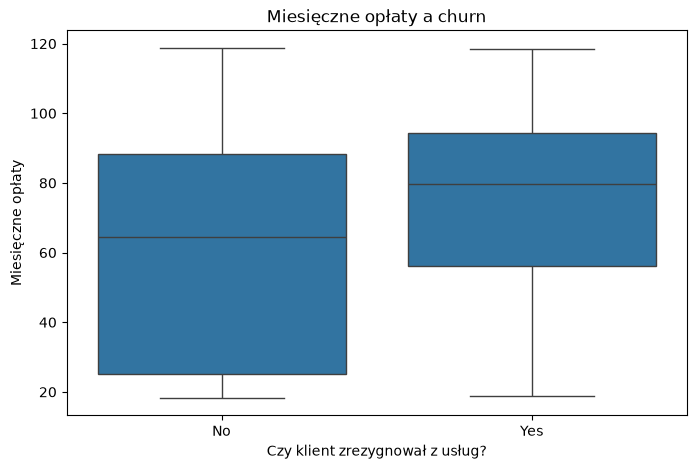

In [70]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Miesięczne opłaty a churn")
plt.xlabel("Czy klient zrezygnował z usług?")
plt.ylabel("Miesięczne opłaty")
plt.show()


##### `MonthlyCharges` a churn - wniosek

Klienci, którzy zrezygnowali z usług, mieli na ogół wyższe miesięczne opłaty niż klienci pozostający. Mediana `MonthlyCharges` wynosi około 80 dla grupy `Churn = Yes` i około 64–65 dla `Churn = No`. Rozkłady częściowo się pokrywają, dlatego wysokość opłat nie stanowi samodzielnego wyjaśnienia churnu.

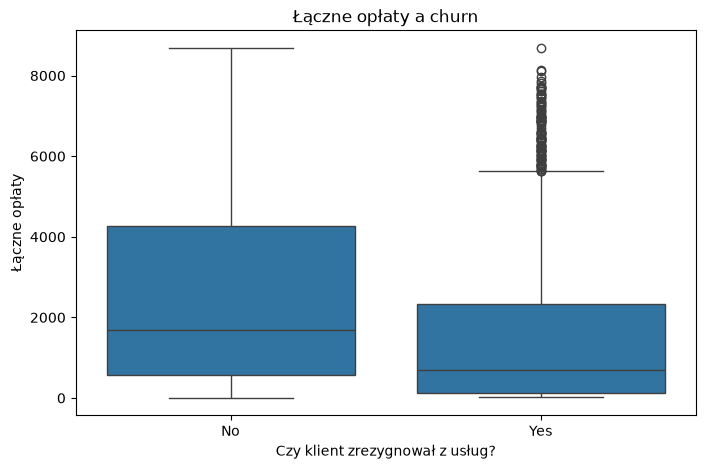

In [71]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Łączne opłaty a churn")
plt.xlabel("Czy klient zrezygnował z usług?")
plt.ylabel("Łączne opłaty")
plt.show()


#### `TotalCharges` a churn - wniosek

Klienci, którzy zrezygnowali z usług, mieli na ogół niższe łączne opłaty (`TotalCharges`) niż klienci pozostający. Mediana jest wyraźnie niższa w grupie `Churn = Yes`. Wynik należy interpretować z uwzględnieniem stażu klienta (`tenure`), ponieważ łączne opłaty zależą zarówno od wysokości opłat miesięcznych, jak i długości korzystania z usług.

### Analiza zmiennych kategorycznych względem Churn

Dla poszczególnych kategorii zostanie policzona liczba klientów oraz odsetek rezygnacji z usług. Pozwala to porównać częstość churnu między grupami klientów.

In [72]:

for col in categorical_cols:
    summary = pd.DataFrame({
        "Liczebność": df.groupby(
            col, dropna=False
        )["Churn"].size(),

        "Churn (%)": (
            df.groupby(col, dropna=False)["Churn"]
            .apply(lambda x: (x == "Yes").mean() * 100)
        )
    })

    print(f"\n--- {col} ---")
    display(summary.round(1))


--- gender ---


,Liczebność,Churn (%)
gender,,
Female,3488,26.9
Male,3555,26.2



--- SeniorCitizen ---


,Liczebność,Churn (%)
SeniorCitizen,,
0,5901,23.6
1,1142,41.7



--- Partner ---


...

,Liczebność,Churn (%)
Contract,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8



--- PaperlessBilling ---


,Liczebność,Churn (%)
PaperlessBilling,,
No,2872,16.3
Yes,4171,33.6



--- PaymentMethod ---


,Liczebność,Churn (%)
PaymentMethod,,
Bank transfer (automatic),1544,16.7
Credit card (automatic),1522,15.2
Electronic check,2365,45.3
Mailed check,1612,19.1


### Wnioski z przeglądu cech kategorycznych

Wstępna analiza wykazała wyraźne różnice w odsetku churnu pomiędzy wybranymi kategoriami. Największy odsetek odejść odnotowano wśród klientów z umową miesięczną (42,7%) oraz korzystających z elektronicznego czeku jako metody płatności (45,3%). Podwyższony churn zaobserwowano również wśród klientów korzystających ze światłowodu (41,9%) oraz nieposiadających usług OnlineSecurity (41,8%) i TechSupport (41,6%).

Niższy odsetek churnu występował m.in. wśród klientów z umowami dwuletnimi (2,8%) oraz posiadających usługi OnlineSecurity (14,6%) i TechSupport (15,2%). Widoczne były także różnice związane z obecnością partnera lub osób na utrzymaniu.

Nie wszystkie cechy wykazywały równie wyraźne różnice, np. odsetki churnu dla obu kategorii zmiennej gender były zbliżone (26,9% i 26,2%).

Wyniki mają charakter opisowy i nie wskazują na związki przyczynowe. Poszczególne cechy mogą być ze sobą powiązane, dlatego ich znaczenie należy ocenić również na etapie modelowania.

## Podsumowanie EDA i wybór cech do dalszej analizy

Przeprowadzona analiza eksploracyjna pozwoliła wskazać cechy, których kategorie różnią się pod względem odsetka rezygnacji klientów. Na tej podstawie wybrano obszary wymagające szczególnej uwagi na dalszym etapie projektu.

**Cechy i zależności wybrane do dalszej analizy:**

- **`Contract`** — zaobserwowano wyraźne różnice w odsetku churnu pomiędzy klientami posiadającymi umowy miesięczne, roczne i dwuletnie.
- **`tenure`** — klienci rezygnujący z usług mieli na ogół krótszy staż niż klienci pozostający.
- **`MonthlyCharges`** — klienci rezygnujący z usług mieli na ogół wyższe opłaty miesięczne.
- **`TotalCharges`** — klienci rezygnujący z usług mieli na ogół niższe łączne opłaty; zależność tę należy interpretować z uwzględnieniem stażu klienta.
- **`InternetService`** — zaobserwowano różnice w odsetku churnu pomiędzy klientami korzystającymi ze światłowodu, DSL oraz niekorzystającymi z internetu.
- **`TechSupport` i `OnlineSecurity`** — brak tych usług współwystępował z wyższym odsetkiem churnu.
- **`PaymentMethod`** — najwyższy odsetek churnu zaobserwowano wśród klientów korzystających z elektronicznego czeku.

Wybór ten opiera się na obserwowanych różnicach w danych i służy ukierunkowaniu dalszej interpretacji wyników. Na obecnym etapie nie oznacza to jednak, że wymienione cechy powodują rezygnację ani że są już potwierdzonymi predyktorami modelu.

Na etapie modelowania do zbioru cech wejściowych zostaną początkowo włączone wszystkie cechy opisujące klientów i ich usługi, z wyjątkiem identyfikatora `customerID`. Zmienna `Churn` będzie zmienną docelową. Znaczenie predykcyjne cech zostanie ocenione na podstawie wyników modeli.

_________________________________________________________________________________________________________________________________________________________


## Przygotowanie danych do modelowania

Celem tego etapu jest przygotowanie danych do budowy modeli klasyfikacyjnych, które będą przewidywać, czy klient zrezygnuje z usług operatora.

Zmienną docelową będzie `Churn`, natomiast jako cechy wejściowe wykorzystane zostaną informacje o klientach i ich usługach. Identyfikator `customerID` zostanie wykluczony, ponieważ pełni funkcję identyfikacyjną, a nie opisową.

Dane zostaną podzielone na zbiór treningowy i testowy. Następnie przygotowany zostanie proces przetwarzania zmiennych (data preprocessing), który będzie można wykorzystać w kolejnych modelach.


#####  Import `scikit-learn`

Do przygotowania danych, budowy modeli klasyfikacyjnych i oceny ich wyników wykorzystane zostaną narzędzia biblioteki `scikit-learn`.

In [73]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

##### Podział danych na zbiór treningowy i testowy

Zbiór danych zostanie podzielony na część treningową, wykorzystywaną do uczenia modelu, oraz testową, służącą do oceny jego skuteczności na danych niewykorzystanych podczas uczenia.

In [74]:
# Zmienna docelowa
y = df["Churn"].map({"No": 0, "Yes": 1})

# Cechy wejściowe — bez identyfikatora i zmiennej docelowej
X = df.drop(columns=["customerID", "Churn"])

# Podział na cechy numeryczne i kategoryczne
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

# Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Rozmiar zbioru treningowego:", X_train.shape)
print("Rozmiar zbioru testowego:", X_test.shape)
print("\nRozkład Churn w zbiorze treningowym:")
print(y_train.value_counts(normalize=True).round(3))


Rozmiar zbioru treningowego: (5634, 19)
Rozmiar zbioru testowego: (1409, 19)

Rozkład Churn w zbiorze treningowym:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


##### Przygotowanie zmiennych do modelowania (data preprocessing)

Aby przygotować dane do modelowania, zmienne liczbowe zostaną przeskalowane, a zmienne kategoryczne przekształcone do postaci liczbowej, którą mogą wykorzystywać algorytmy uczenia maszynowego.

In [75]:
# Przetwarzanie cech numerycznych
numeric_transformer = StandardScaler()

# Przetwarzanie cech kategorycznych
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Połączenie obu procesów
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

##### Model bazowy

Jako punkt odniesienia zostanie wykorzystany model bazowy, który zawsze przewiduje najczęściej występującą klasę, co pozwoli ocenić, czy bardziej zaawansowany model zapewnia lepsze wyniki.

In [76]:
# DummyClassifier - zaimportowane wcześniej

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

print("Accuracy modelu bazowego:",
      round(accuracy_score(y_test, y_pred_baseline), 3))

print("\nRaport klasyfikacji:")
print(classification_report(
    y_test,
    y_pred_baseline,
    zero_division=0
))

Accuracy modelu bazowego: 0.735

Raport klasyfikacji:
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1035
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



##### **Pierwszy model klasyfikacyjny - regresja logistyczna**

Regresja logistyczna zostanie wykorzystana jako pierwszy model klasyfikacyjny, którego zadaniem będzie przewidywanie rezygnacji klienta na podstawie przygotowanych cech wejściowych.

In [77]:
# LogisticRegression - zaimportowane wcześniej

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

print("Raport klasyfikacji — regresja logistyczna:")
print(classification_report(
    y_test,
    y_pred_logistic,
    zero_division=0
))

Raport klasyfikacji — regresja logistyczna:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



##### Obserwacje — model bazowy a regresja logistyczna

- **Model bazowy (`DummyClassifier`)** osiągnął accuracy **73,5%**, ale nie wykrył żadnego klienta odchodzącego (recall i F1 dla klasy `Churn = 1` wyniosły 0).
- **Regresja logistyczna** osiągnęła accuracy **81%** i poprawiła wykrywanie klientów odchodzących: recall wyniósł **56%**, precision **66%**, a F1-score **0,60**.
- Regresja logistyczna lepiej rozpoznaje klientów zagrożonych odejściem, zamiast jedynie przewidywać klasę większościową.
- Model bazowy wydaje się mało użyteczny w analizie churnu. Regresja logistyczna stanowi znacznie lepszy punkt odniesienia dla kolejnych modeli.

##### **Drugi model klasyfikacyjny - Random Forest**

Random Forest zostanie wykorzystany jako drugi model klasyfikacyjny, aby porównać jego skuteczność z regresją logistyczną i sprawdzić, czy pozwala lepiej identyfikować klientów rezygnujących z usług.

In [78]:
# RandomForestClassifier - zaimportowane wcześniej

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

print("Raport klasyfikacji — Random Forest:")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))


Raport klasyfikacji — Random Forest:
              precision    recall  f1-score   support

           0       0.86      0.81      0.84      1035
           1       0.55      0.62      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.77      0.76      0.77      1409



##### Obserwacje — Random Forest

- Model osiągnął accuracy **76%**, czyli mniej niż regresja logistyczna (**81%**).
- Dla klasy `Churn = 1` uzyskał recall **62%** — wykrywa więc większy odsetek odchodzących klientów niż regresja logistyczna (**56%**).
- Jednocześnie precision spadło z **66% do 55%**, co oznacza, że większa część klientów oznaczonych jako zagrożeni odejściem faktycznie nie odchodzi.
- F1-score dla klasy `Churn = 1` wyniósł **0,58**, nieco mniej niż w regresji logistycznej (**0,60**).

Random Forest lepiej wychwytuje odchodzących klientów, ale robi to kosztem większej liczby fałszywych alarmów. Na podstawie obecnych wyników regresja logistyczna osiąga lepszy kompromis między precision i recall, natomiast wybór modelu zależy od biznesowego kosztu niewykrycia churnu i błędnego wskazania klienta jako zagrożonego odejściem.